# Learning symmetry-reduced dynamics on a sphere

Points on the same latitude differ only by a rotation or reflection about the vertical axis. Can a learned scalar coordinate describe how these entire circles move, and can its recurrent sets recover the local topological indices on the sphere?

This example follows one model from the differential equation through its learned encoder, time-step map, and orbit decoder to a comparison of Morse graphs. The physical height is denoted by $z$. The learned coordinate is denoted by $\xi$ in formulas and by $q$ in the plots. They are different coordinates on the same family of circles.


## Run this example

The saved outputs can be read without running Python. To reproduce them, install the two pinned environments using [the setup instructions](../README.md#run-locally), choose the `code-kaito/.venv` kernel, and run the cells in order. The default loads the supplied trained model and does not retrain it.

The setup cell finds the example folder and calls `workspace` from `src/notebook_support.py`. It restores the bundled model weights and numerical evidence, checks dependency versions and input hashes, and prepares plotting caches. `ROOT` is the example folder. `EXAMPLES` and `DATA` identify the checked numerical dependency and its inputs. No model is fitted in this cell.


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
ROOT, EXAMPLES, DATA = workspace()


Pinned dependencies 21acca6 and numerical input checksums verified.


## Sphere flow and physical quotient

For $p=(x,y,z)\in S^2=\{p\in\mathbb R^3:\|p\|=1\}$ and $e_3=(0,0,1)$, consider
$$\dot p=0.6e_3\times p+z(0.4^2-z^2)(e_3-zp).$$
The physical quotient $q:S^2\to[-1,1]$, $q(p)=p_3$, identifies the circles of constant height. Its flow maps $h_t:[-1,1]\to[-1,1]$ solve
$$\dot z=z(0.4^2-z^2)(1-z^2).$$
Removing the known rotation gives an $O(2)$-equivariant flow $F_t:S^2\to S^2$ with this same height equation. Training uses $F_1$, and the CMGDB comparison uses $h_{10}$.

For example, $(\sqrt3/2,0,1/2)$ and $(0,\sqrt3/2,1/2)$ both have height $1/2$ and belong to the same orbit. Their quotient velocity is
$$\dot z=\tfrac12(0.16-0.25)(1-0.25)=-0.03375,$$
so that latitude moves toward $z=0.4$. Factoring the height equation gives fixed heights $-1,-0.4,0,0.4,1$. The poles and equator repel in height, while the circles at $\pm0.4$ attract. Rotation along the attracting circles continues.

The next cell evaluates the three-dimensional vector field on the visible hemisphere. It projects both the sphere and its tangent vectors onto a plane viewed from an elevation of $18^\circ$. The projection $P:\mathbb R^3\to\mathbb R^2$ is $P(p)=(p\cdot u,p\cdot w)$, where $u,w$ are orthonormal screen directions. The unit vector $d$ points toward the viewer, so $p\cdot d\geq0$ identifies the front hemisphere.

Arrows have equal length in three dimensions before projection, showing direction rather than speed. This is a vector-field plot, not a collection of simulated trajectories. Faint portions of the invariant circles lie behind the sphere. NumPy constructs the points and vectors, and Matplotlib draws their projections. All geometry and plotting instructions are in the cell.


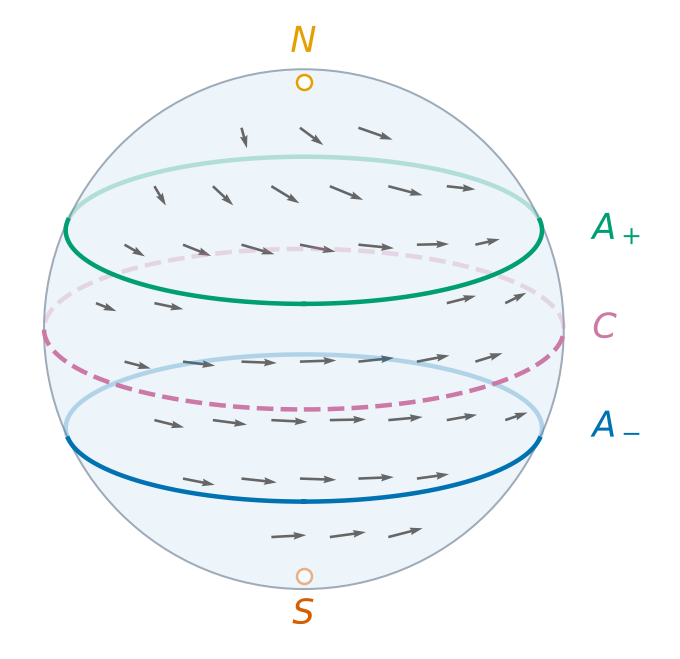

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import Image, display

# Evaluate the stated vector field at an array of sphere points.
def sphere_field(points):
    z = points[:, 2]
    rotation = 0.6 * np.column_stack((-points[:, 1], points[:, 0], 0*z))
    return rotation + (z*(0.16-z*z))[:, None] * (np.array([0, 0, 1])-z[:, None]*points)

# Orthographic camera and screen coordinates.
elevation = np.deg2rad(18)
d = np.array([np.cos(elevation), 0, np.sin(elevation)])
u = np.array([0, 1, 0])
w = np.cross(d, u)
def project(points):
    return np.column_stack((points @ u, points @ w))

# Lift a staggered screen grid to the front unit hemisphere.
points = []
for row, b in enumerate(np.linspace(-0.8, 0.775, 8)):
    for a in np.arange(-0.8 + (row % 2)*0.11, 0.86, 0.225):
        if a*a+b*b < 0.87**2:
            p = a*u + b*w + np.sqrt(1-a*a-b*b)*d
            if np.min(np.abs(p[2]-np.array([-0.4, 0, 0.4]))) > 0.04:
                points.append(p)
points = np.array(points)
vectors = sphere_field(points)
assert np.max(np.abs(np.sum(points*vectors, axis=1))) < 1e-12  # tangency
arrows = project(0.14*vectors / np.linalg.norm(vectors, axis=1)[:, None])
base = project(points)

fig, ax = plt.subplots(figsize=(5.4, 4.5))
ax.add_patch(Circle((0, 0), 1, facecolor='#edf4fa', edgecolor='#9eabb8', lw=0.8))
ax.quiver(base[:, 0], base[:, 1], arrows[:, 0], arrows[:, 1],
          angles='xy', scale_units='xy', scale=1, width=0.004, color='0.4')
phi = np.linspace(0, 2*np.pi, 1001)
for height, color, label in [(-0.4, '#0072b2', r'$A_-$'),
                              (0, '#cc79a7', '$C$'), (0.4, '#009e73', r'$A_+$')]:
    radius = np.sqrt(1-height**2)
    circle = np.column_stack((radius*np.cos(phi), radius*np.sin(phi), height+0*phi))
    screen = project(circle)
    for front in (False, True):
        visible = (circle @ d >= 0) == front
        line = np.where(visible[:, None], screen, np.nan)
        ax.plot(line[:, 0], line[:, 1], '--' if height == 0 else '-',
                color=color, alpha=1 if front else 0.25, lw=1.8)
    ax.text(1.11, height*np.cos(elevation), label, color=color, fontsize=14, va='center')
for height, label, color in [(1, '$N$', '#e69f00'), (-1, '$S$', '#d55e00')]:
    x, y = project(np.array([[0, 0, height]]))[0]
    ax.plot(x, y, 'o', mfc='white', mec=color, alpha=1 if height > 0 else 0.45)
    ax.text(0, 1.10*height, label, ha='center', va='center', fontsize=14, color=color)
ax.set(aspect='equal', xlim=(-1.1, 1.38), ylim=(-1.2, 1.2))
ax.axis('off')
figure_dir = ROOT / 'build/notebooks/sphere/analytical'
figure_dir.mkdir(parents=True, exist_ok=True)
for extension in ('png', 'pdf', 'svg'):
    fig.savefig(figure_dir / f'sphere-field.{extension}', dpi=180, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(figure_dir / 'sphere-field.png'), width=540))

### Integrate the height equation

To compute $h_3(z_0)$, start the scalar ODE at $z_0$ and integrate for three time units. `solve_ivp` from SciPy performs adaptive numerical integration with the displayed tolerances. Passing the independent initial heights as a vector computes the whole curve in one call. The extra points near the poles resolve its steep ends.

The gray diagonal is the identity. Its intersections with $h_3$ are the five fixed heights. Filled markers indicate attraction in height, and open markers indicate repulsion. The assertions check these fixed values and agreement with a second integration at tighter tolerances on the plotted grid. They are numerical checks, not uniform error bounds.


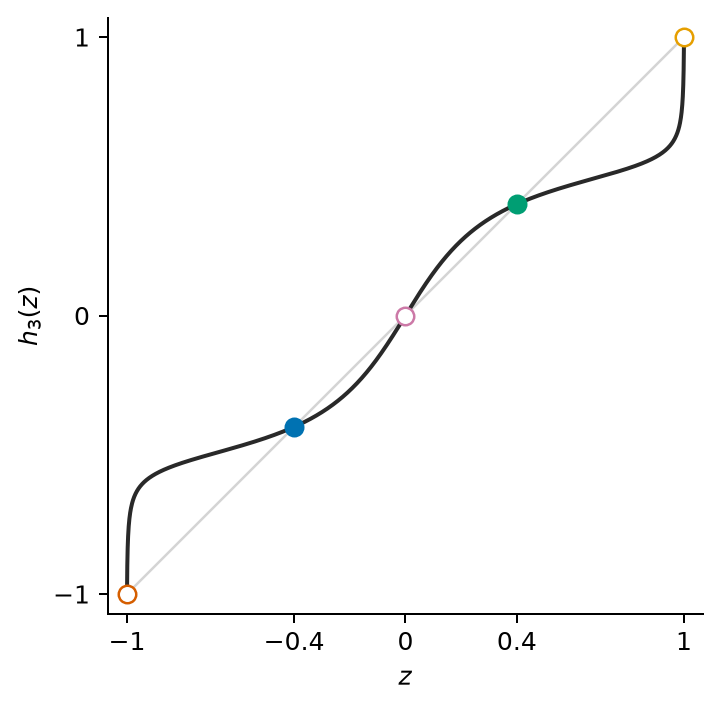

In [3]:
from scipy.integrate import solve_ivp

def height_velocity(t, z):
    return z*(0.16-z*z)*(1-z*z)

def height_flow(z0, duration, rtol=1e-10, atol=1e-12):
    solution = solve_ivp(height_velocity, (0, duration), np.asarray(z0, dtype=float),
                         method='DOP853', rtol=rtol, atol=atol)
    assert solution.success, solution.message
    return solution.y[:, -1]

z = np.unique(np.r_[np.linspace(-1, 1, 1401),
                    1-10.**(-np.linspace(1, 12, 300)),
                    -1+10.**(-np.linspace(1, 12, 300)), -0.4, 0.4])
h = height_flow(z, 3)
fixed = np.array([-1, -0.4, 0, 0.4, 1])
assert np.max(np.abs(height_flow(fixed, 3)-fixed)) < 1e-12
assert np.max(np.abs(h-height_flow(z, 3, rtol=1e-12, atol=1e-14))) < 1e-8
assert np.min(np.diff(h)) >= -1e-10

fig, ax = plt.subplots(figsize=(4.6, 4.3))
ax.plot([-1, 1], [-1, 1], color='0.83', lw=1)
ax.plot(z, h, color='0.16', lw=1.6)
colors = ['#d55e00', '#0072b2', '#cc79a7', '#009e73', '#e69f00']
for value, color in zip(fixed, colors):
    ax.plot(value, value, 'o', mec=color, mfc=color if abs(value) == 0.4 else 'white', ms=7)
ax.set(aspect='equal', xlim=(-1.07, 1.07), ylim=(-1.07, 1.07), xlabel='$z$', ylabel='$h_3(z)$')
ax.set_xticks(fixed, ['−1', '−0.4', '0', '0.4', '1'])
ax.set_yticks([-1, 0, 1])
ax.spines[['top', 'right']].set_visible(False)
for extension in ('png', 'pdf', 'svg'):
    fig.savefig(figure_dir / f'height-map.{extension}', dpi=180, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(figure_dir / 'height-map.png'), width=460))

## Learn coordinates, dynamics, and an orbit representative

The encoder assigns the same scalar to all points on an $O(2)$ orbit. The learned time-step map advances that scalar. The decoder chooses one point on the predicted orbit, so it does not attempt to recover the original longitude.

An equivariant multilayer perceptron (EMLP) is a neural network whose layers respect a specified group action. Here its encoder output is invariant. Objax supplies automatic differentiation and optimization. The formulas below specify the output transformations around those networks.

The invariant encoder $E_\theta:S^2\to\mathbb R$ takes raw states. An invariant EMLP $N_\theta:\mathbb R^3\to\mathbb R$ receives the reordered state $(z,x,y)$ divided by $S\in\mathbb R^{3\times3}$, a diagonal matrix with the root-mean-square scale of $z$ and one shared root-mean-square scale for $x,y$, computed over both members of the training pairs. Define $\eta_\theta:S^2\to(-1,1)$ by $\eta_\theta(p)=\tanh N_\theta(S^{-1}(z,x,y))$, $c=(\eta_\theta(-e_3)+\eta_\theta(e_3))/2$, and $b=(\eta_\theta(e_3)-\eta_\theta(-e_3))/2$. The implementation uses a signed floor $|b|\ge10^{-5}$ and sets
$$E_\theta(p)=\frac{\eta_\theta(p)-c}{b}.$$
For this fit the floor is inactive and the poles map to $-1$ and $1$. This calibration alone does not prove $Z=E_\theta(S^2)\subseteq[-1,1]$. Range and monotonicity checks below are sampled.

For scalar networks $N_\psi,N_\phi:\mathbb R\to\mathbb R$, the shift $t_\psi:\mathbb R\to(-1,1)$ defines a map $f_\psi:[-1,1]\to[-1,1]$ that fixes the endpoints,
$$t_\psi(\xi)=\tanh\!\left(3\tanh(N_\psi(\xi)/3)\right).$$
$$f_\psi(\xi)=\frac{\xi+t_\psi(\xi)}{1+\xi t_\psi(\xi)}.$$
The height decoder $\widehat z_\phi:\mathbb R\to(-1,1)$ and representative decoder $D_\phi:\mathbb R\to S^2$ are
$$\widehat z_\phi(\xi)=\tanh N_\phi(b\xi+c).$$
$$D_\phi(\xi)=(\sqrt{1-\widehat z_\phi(\xi)^2},0,\widehat z_\phi(\xi)).$$
The decoder chooses longitude zero. For two sphere states of heights $z,\widehat z$, their squared orbit distance is $(z-\widehat z)^2+(\sqrt{1-z^2}-\sqrt{1-\widehat z^2})^2$.

The desired relation is $f_\psi(E_\theta(p))\approx E_\theta(F_1(p))$.


## Training objective

With $\tau=1$, use pairs $x^+=F_\tau(x)$. Let $u$ range over both members of the training pairs. The state scale is $s=1$ and the latent dimension is $m=1$. Write $E=E_\theta$, $f=f_\psi$, and $D=D_\phi$. The orbit distance $d_G:\mathbb R^{3}\times\mathbb R^{3}\to[0,\infty)$ minimizes Euclidean distance over the stated orthogonal action. The training loss is

$$L=L_{\rm rec}+L_{\rm pred}+L_{\rm con}+0.1L_{\rm cyc}+0.01L_{\rm spread},$$
$$L_{\rm rec}=\mathbb E_u\frac{d_G(D(E(u)),u)^2}{s^2}.$$
$$L_{\rm pred}=\mathbb E_x\frac{d_G(D(f(E(x))),x^+)^2}{s^2},$$
$$L_{\rm con}=\frac1m\mathbb E_x\|f(E(x))-E(x^+)\|^2.$$
$$L_{\rm cyc}=\frac1m\mathbb E_u\|E(D(E(u)))-E(u)\|^2,$$
$$L_{\rm spread}=\frac1m\sum_{j=1}^m\bigl(\operatorname{std}_u E_j(u)-0.5\bigr)^2.$$

Cycle evaluation uses the encoder formula on the decoded representatives.

Reconstruction checks whether the encoder and decoder preserve the orbit of a state. Prediction advances the encoded state before decoding. Consistency compares that latent prediction with the encoding of the observed next state. Cycle consistency encodes a decoded representative again. The spread term discourages collapse to a constant latent coordinate. Expectations and standard deviations in the training loss are empirical batch quantities. The optimizer is Adam, and the saved weights minimize the recorded validation loss.


## Load the trained model

All three networks use EMLP/Objax, width 32 and two layers. Joint training uses batches of 256, 8,000 updates, and learning rate decaying from $10^{-3}$ to $2\cdot10^{-5}$.

The 4,096 training points are independent uniform sphere samples, without repeated poles. Pole calibration is separate from training pairs. Validation has 512 points, including 32 copies of each pole, and testing has 512 uniform sphere points. Validation loss selects the checkpoint. No height targets or CMGDB results enter selection.

`fit_quotient`, from `src/quotient_fitting.py`, resolves this configuration to its supplied checkpoint, verifies the weights, and returns its fit directory. With `retrain=False`, the curve below is the saved training history. Blue is batch loss and orange is validation loss. The architecture and loss used to create the checkpoint are specified above. Changing to `retrain=True` runs that training configuration again.


Loaded raw-state sphere quotient fit (seed 0).


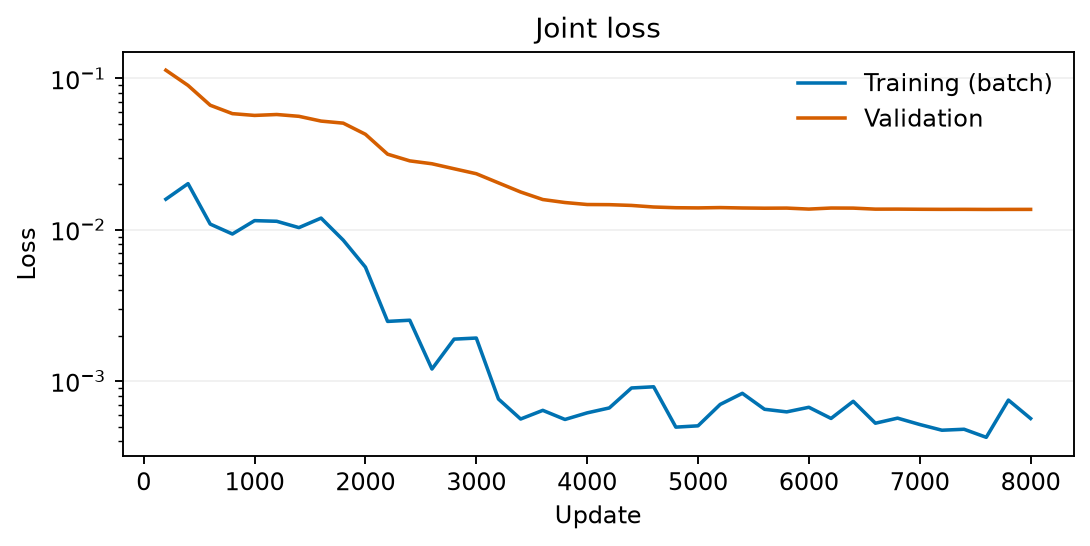

In [4]:
from quotient_fitting import fit_quotient
fit = fit_quotient("sphere", training="joint", seed=0, joint_steps=8000,
                   train_starts=4096, training_boundary_fraction=0.0,
                   time_step=1.0, cmgdb_iterations=10, width=32, layers=2, batch_size=256,
                   learning_rate=1e-3, minimum_learning_rate=2e-5,
                   cycle_weight=0.1, spread_weight=0.01,
                   retrain=False, live=True)


## Read the learned model

`show_quotient_fit`, from `src/quotient_notebook.py`, reads the saved evaluation arrays and displays three panels. The left panel compares physical height $z$ with learned coordinate $q=E_\theta(p)$. The middle compares $f_\psi^{10}$ with the encoded time-ten ODE image. The right compares decoded height with true height on the test set.

The table reports root-mean-square orbit distance, divided by sphere radius one. “One step” predicts from a test state once. “Ten steps” repeatedly advances the learned coordinate before decoding. All three errors use the held-out test states, not the validation states used to choose the weights.


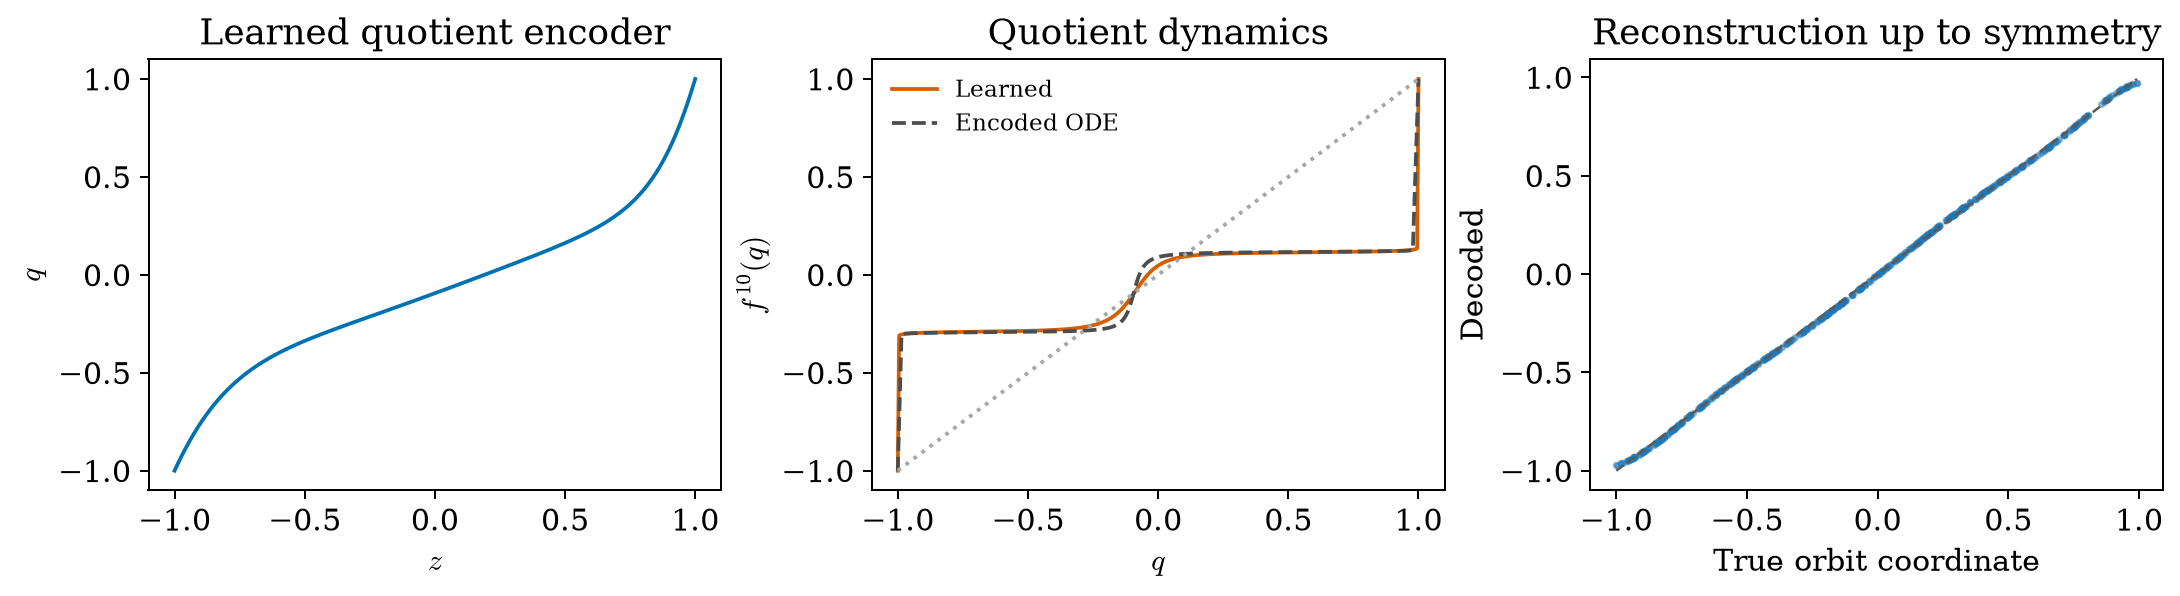

Held-out orbit RMS / state scale,Reconstruction,One step,Ten steps
Raw states,1.81%,1.05%,5.42%


In [5]:
from quotient_notebook import show_quotient_fit
show_quotient_fit(fit)


## Compare recurrent dynamics

Each interval cell is sampled at five points. The hull of its images under $f_\psi^{10}$ is inflated by $10^{-9}$ and clipped to $[-1,1]$. CMGDB forms the directed graph and computes relative-chain indices over $\mathbb F_5$. Nearby components are grouped with their connecting cells, and each aggregate index is recomputed. The 128, 256, 512, and 1,024 cell grids have 9, 8, 9, and 7 native components and five aggregates each. Sampled hulls are not certified outer bounds.

### Reading the Morse graphs

A **Morse set** collects recurrent behavior such as an equilibrium or an invariant circle. In the cell graph, recurrent strongly connected components give the **native** nodes. An arrow records a possible transition in this finite graph. It need not prove an orbit of the ODE exists. An **aggregate** joins nearby nodes together with their connecting cells, after which its index is recomputed.

The Conley index records the topology of a neighborhood relative to the part of its boundary through which trajectories leave. Its homology groups $H_k$ are vector spaces over $\mathbb F_5$, the field of integers modulo five. A node annotation lists the index-map polynomials in degrees $0,1,2,\ldots$. In these figures, `0` means no nonzero Conley homology in that degree and `x-1` means a one-dimensional class with identity map. The `x` in this label is a formal polynomial variable, not a state coordinate. For example, `(0, x-1, 0)` has only $H_1=\mathbb F_5$. Numbers attached to native nodes are component identifiers, not coordinates or stability ranks.

### Recover the fiber contribution

On the sphere represented as $([-1,1]\times S^1)/\!\sim$, with each endpoint circle collapsed, the specified lift $\widetilde F:S^2\to S^2$ is
$$\widetilde F(\xi,\vartheta)=(f_\psi(\xi),\vartheta+0.6).$$
Its rotation is prescribed. The nonzero local Conley homology groups are $H_2$ at the poles, $H_1,H_2$ at the central repelling circle, and $H_0,H_1$ at the attracting circles, with identity maps over $\mathbb F_5$. The pole indices vanish in the quotient. Arb interval arithmetic bounds verify local isolation and continuation for this specified lift. Here local means a neighborhood of each indicated invariant set.

`quotient_domain_study`, from `src/quotient_domain_notebook.py`, takes the saved fit and grid levels, checks their identity against the saved study, and returns paths to matching results. If no matching study exists, it evaluates the model on the cell samples and runs CMGDB. Level $\ell$ means $2^\ell$ interval cells.

`show_sphere_comparison`, from `src/sphere_comparison.py`, computes numerical encoder preimages of the saved Morse cells, recomputes the aggregate comparison, and draws the two columns. Read downward from the sphere bands to the interval cells, quotient graph, and reconstructed sphere indices. In the learned column the band locations come from the encoder, so they need not equal the analytical heights.


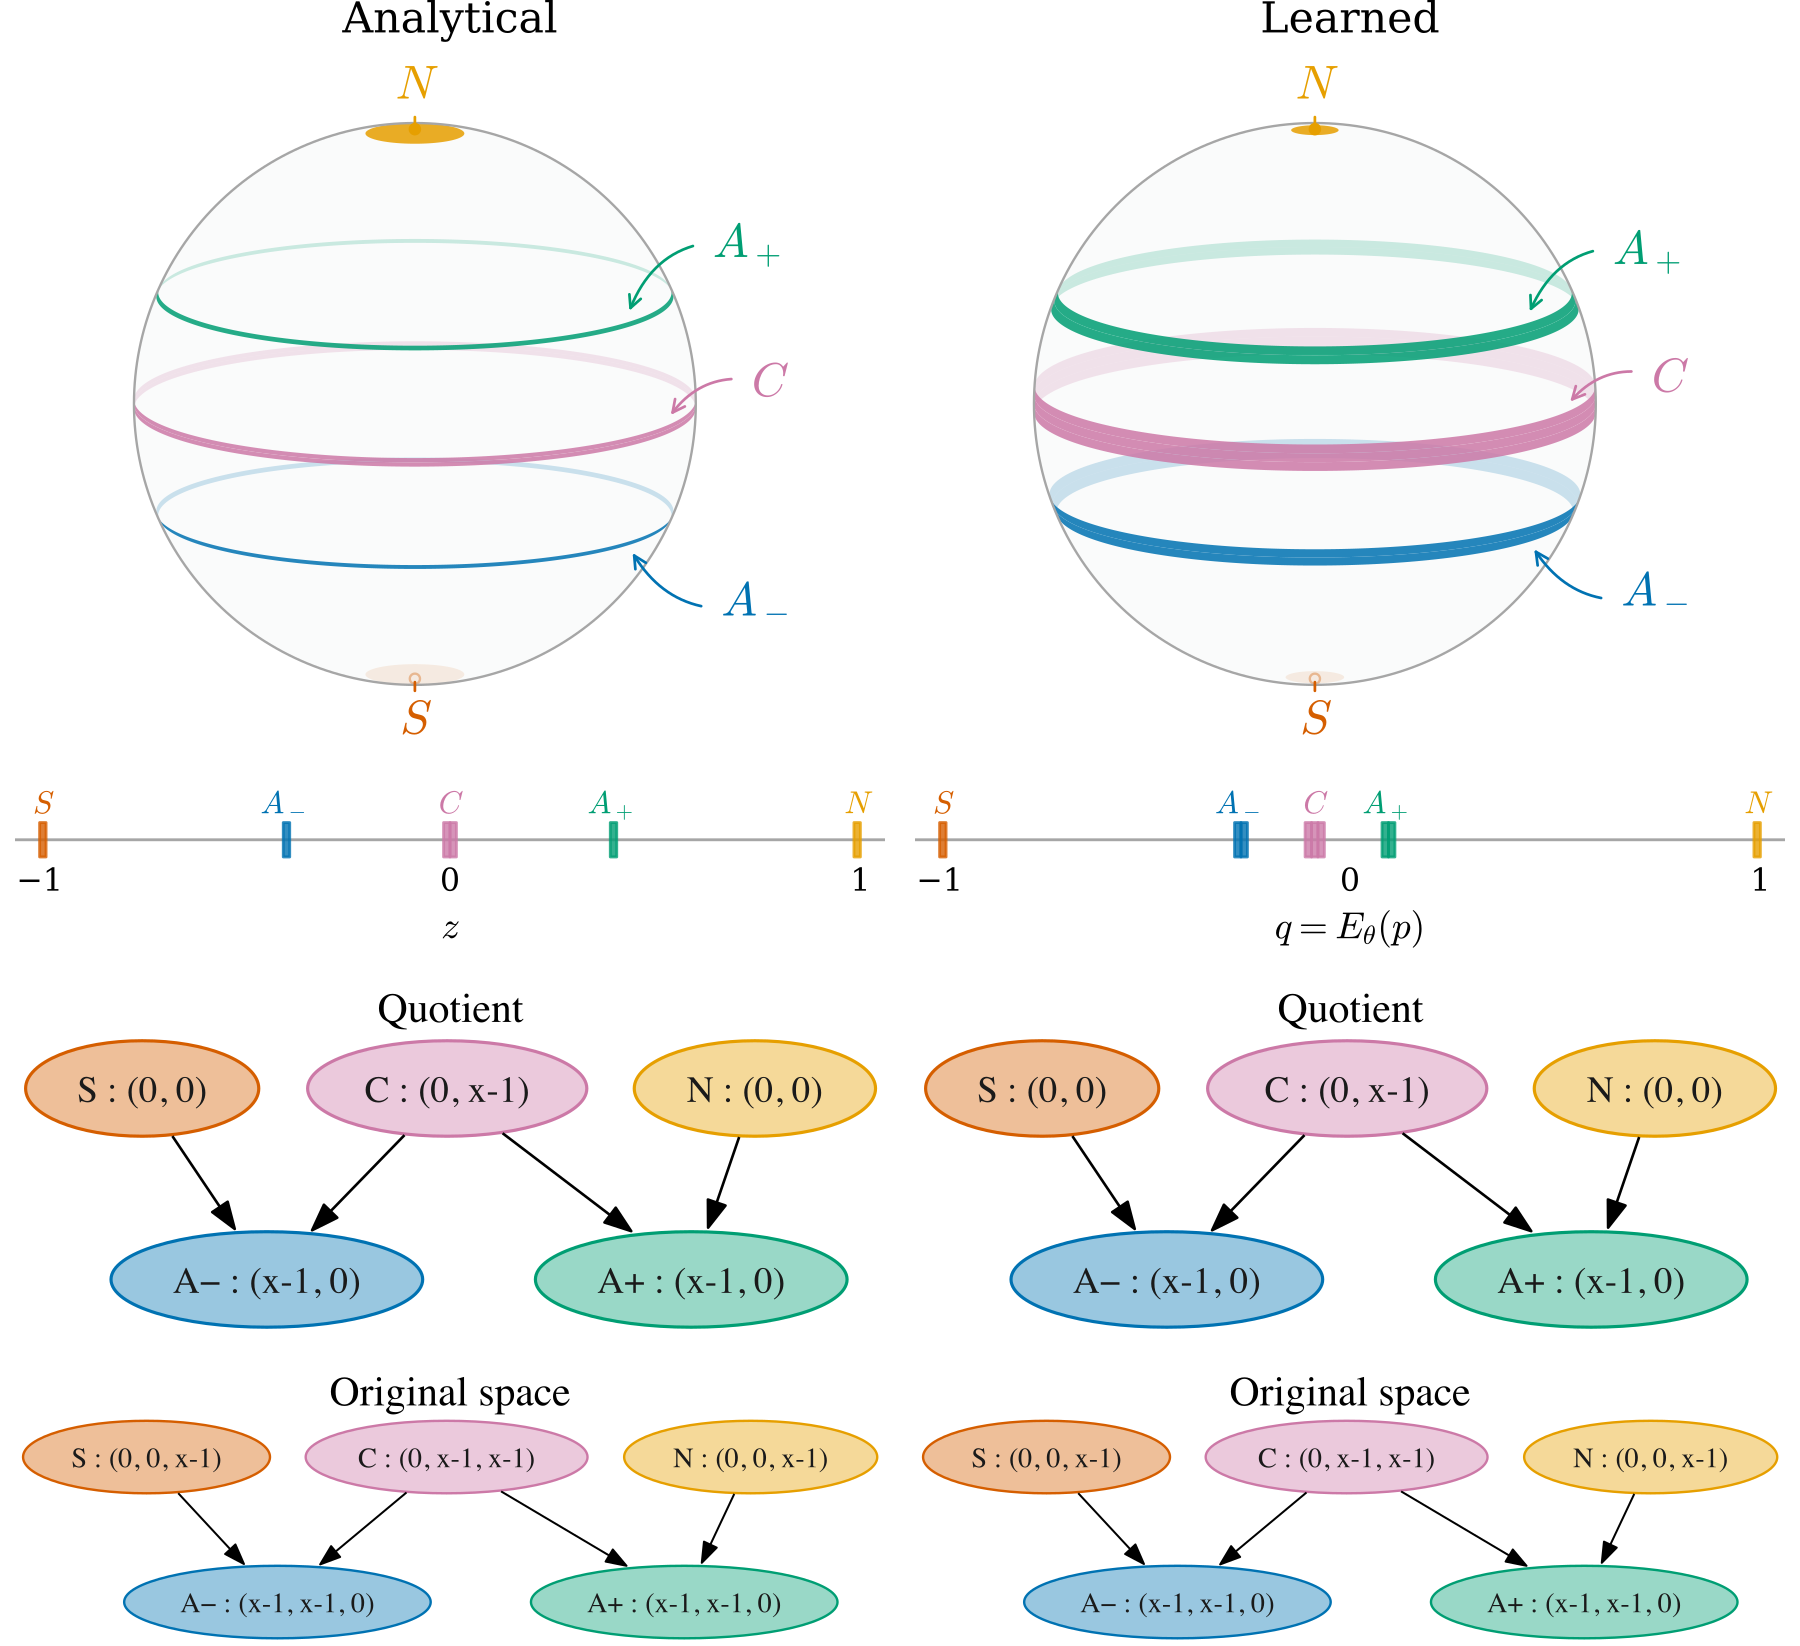

**128 interval cells.** Colored bands are encoder preimages of native Morse cells. The graph rows show recomputed aggregates and the local indices of the specified sphere lift.

In [6]:
from quotient_domain_notebook import quotient_domain_study
from sphere_comparison import show_sphere_comparison
study = quotient_domain_study(fit, levels=(7, 8, 9, 10))
comparison = show_sphere_comparison(fit, study)


## Check the native graphs and fixed points

The five-node comparison groups native components. The following output keeps those original components visible at every tested resolution. The curve plots the **one-step** displacement $f_\psi(\xi)-\xi$, whose zeros are fixed points, even though the cell graphs use ten steps.

`show_domain_comparison`, from `src/quotient_domain_notebook.py`, reads the same study, displays its component-count table and displacement plot, and renders the native graphs. `show_graphs=False` omits a duplicate aggregate comparison.


Grid,Rectangle components,Encoder-image components
128,9,9
256,8,8
512,9,9
1024,7,7


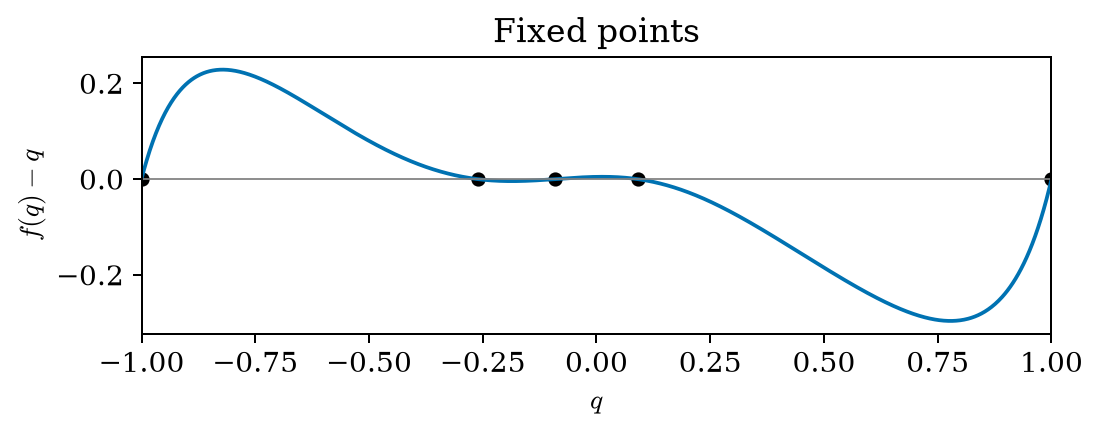

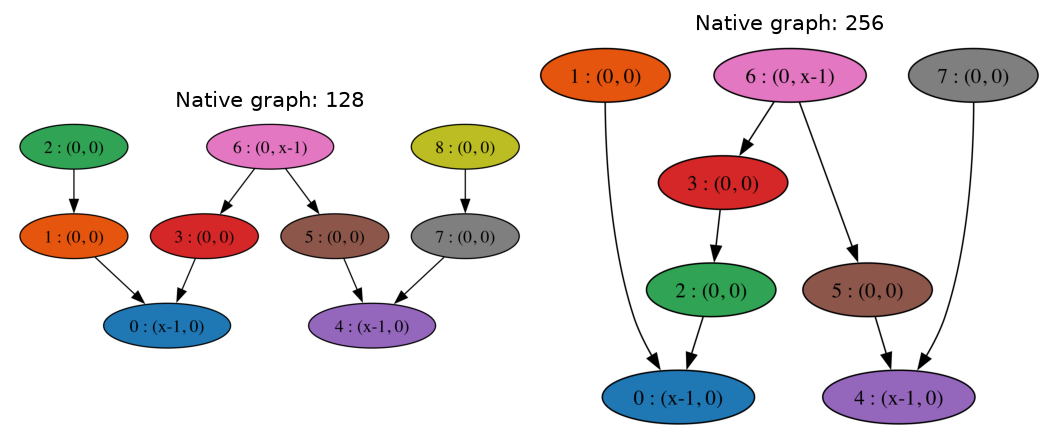

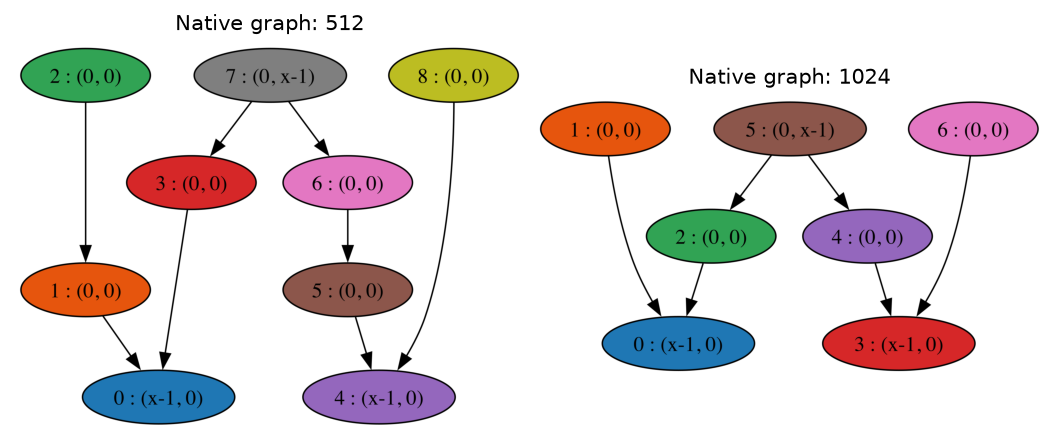

In [7]:
from quotient_domain_notebook import show_domain_comparison
show_domain_comparison(figure_dir, fit, study, show_graphs=False)


## What transfers to the physical flow

The displayed graph is computed from sampled cell-image hulls. The local index bounds concern the explicitly specified lift. To identify its dynamics with the physical ODE through the encoder would also require suitable encoder coordinates and a uniform model-error bound that preserves isolation along a continuation.

At a physical quotient fixed point, choose a representative $x_*$. Since the encoder is invariant, $E(F_\tau(x_*))=E(x_*)$, even if the state rotates along its orbit. Thus $\|f(E(x_*))-E(x_*)\|$ measures failure of the desired commutation relation at that orbit. A small value is a useful diagnostic, but does not bound the error on a neighborhood.

`show_conjugacy_check`, from `src/conjugacy_summary.py`, matches the checkpoint hash to the saved fixed-point evaluations and reports these defects. The geometry count is the number of sampled encoder derivatives (sphere) or Jacobian determinants (O(3)). Positivity on those samples is not a global invertibility proof.


In [8]:
from conjugacy_summary import show_conjugacy_check
show_conjugacy_check(fit)


Quantity,Value
"Largest fixed-point defect, one step",0.0033534
"Largest fixed-point defect, CMGDB horizon",0.0181043
Encoder geometry sample count,2049
